In [ ]:
!wget -q 'https://www.kaggle.com/api/v1/datasets/download/masoudnickparvar/brain-tumor-mri-dataset'
!unzip -q '/content/brain-tumor-mri-dataset'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model
from tensorflow.keras.metrics import Precision, Recall, AUC
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    TensorBoard
)
import matplotlib.pyplot as plt
import numpy as np
import gc

In [ ]:
IMG_SIZE = (256, 256)
BATCH_SIZE = 64
SEED = 42

train_dir = "/content/Training"
test_dir = "/content/Testing"

In [ ]:
# -----------------------------
# Train Dataset (100% Training)
# -----------------------------
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

# -----------------------------
# Validation Dataset (50% Testing)
# -----------------------------
val_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    validation_split=0.5,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="categorical",
    shuffle=True
)

# -----------------------------
# Test Dataset (50% Testing)
# -----------------------------
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    validation_split=0.5,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names

print("\nClasses:", class_names)

Found 5600 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.
Using 800 files for training.
Found 1600 files belonging to 4 classes.
Using 800 files for validation.

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


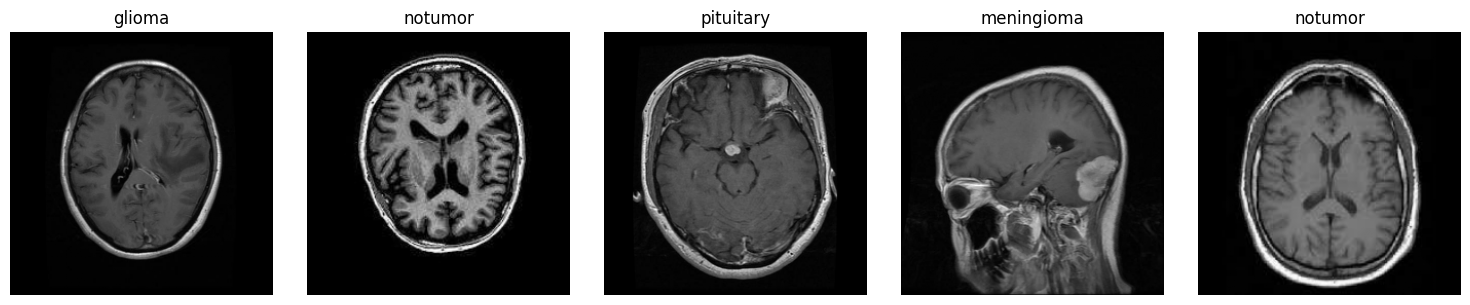

In [ ]:
plt.figure(figsize=(15, 3))

for images, labels in train_ds.take(1):
    for i in range(5):
        plt.subplot(1, 5, i + 1)

        plt.imshow(images[i].numpy().astype("uint8").squeeze(), cmap="gray")
        plt.title(class_names[np.argmax(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Random data augmentation layers ONLY (no Rescaling here on purpose).
#
# NOTE: This Sequential is intentionally kept OUT of the saved/exported
# model. It is applied directly inside the tf.data pipeline (train_ds
# only, see the pipeline cell below), so the .keras file we export later
# never contains these preprocessing layers. That's what was causing the
# "Unrecognized keyword arguments passed to RandomFlip: {'data_format': ...}"
# error when loading the model in an environment with a different Keras
# version -- by keeping these layers out of the saved model entirely, the
# version-mismatch issue can't happen anymore.
data_augmentation = tf.keras.Sequential([

    # Random horizontal flip
    layers.RandomFlip("horizontal"),

    # Random rotation (about ±10 degrees)
    layers.RandomRotation(0.03),

    # Random zoom (±10%)
    layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10
    ),

    # Random translation (±5%)
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),

], name="Data_Augmentation")

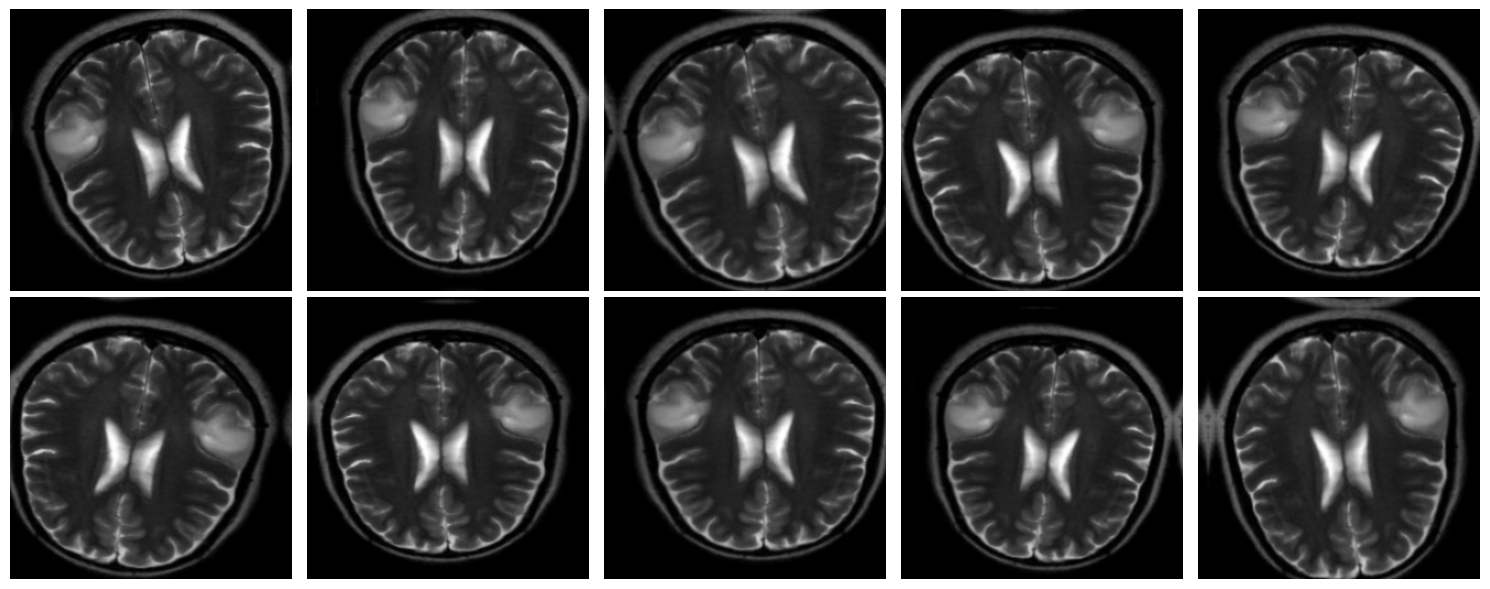

In [ ]:
tf.keras.backend.clear_session()
gc.collect()
for images, labels in train_ds.take(1):

    sample = images[0]

    plt.figure(figsize=(15, 6))

    for i in range(10):
        augmented = data_augmentation(tf.expand_dims(sample, axis=0), training=True)

        plt.subplot(2, 5, i + 1)
        plt.imshow(tf.squeeze(augmented[0]), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

# Augmentation is applied ONLY to the training set, inside the tf.data
# pipeline -- not inside the model. val_ds / test_ds are left untouched
# (no augmentation, no shuffling).
train_ds = (
    train_ds
    .shuffle(1000)
    .map(
        lambda x, y: (data_augmentation(x, training=True), y),
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(buffer_size=AUTOTUNE)
)

val_ds = (
    val_ds
    .prefetch(buffer_size=AUTOTUNE)
)

test_ds = (
    test_ds
    .prefetch(buffer_size=AUTOTUNE)
)

In [ ]:
NUM_CLASSES = len(class_names)

# --------------------------------------------------
# EfficientNetV2B0 Backbone
# --------------------------------------------------
base_model = EfficientNetV2B0(
    weights="imagenet",
    include_top=False,
    input_shape=(256, 256, 3),
    include_preprocessing=False
)

# Freeze Backbone
base_model.trainable = True

# --------------------------------------------------
# Build Model
# --------------------------------------------------
inputs = layers.Input(shape=(256, 256, 1))

# Gray -> RGB
x = layers.Concatenate()([inputs, inputs, inputs])

# Normalize pixel values to [0, 1].
# This is a simple, deterministic layer (no randomness, very stable API),
# so it's safe to keep inside the saved model -- unlike the random
# augmentation layers, it will NOT cause Keras-version deserialization
# issues when loading the model elsewhere.
x = layers.Rescaling(1./255, name="Rescaling")(x)

# Feature Extractor
# (Data augmentation is NOT applied here anymore -- it now happens only
# in the tf.data pipeline above, only for train_ds.)
x = base_model(x, training=False)

# Classification Head
x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.30)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_initializer="he_normal"
)(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_initializer="he_normal"
)(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_initializer="he_normal"
)(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.40)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(inputs, outputs, name="Brain_Tumor_EfficientNetV2B0")

model.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Brain_Tumor_EfficientNetV2B0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256, 256,  │          0 │ input_layer_2[0]… │
│ (Concatenate)       │ 3)                │            │ input_layer_2[0]… │
│                     │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Rescaling           │ (None, 256, 256,  │          0 │ concatenate[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2-b0   │ (None, 8, 8,      │  5,919,312 │ Rescaling[0][0]   │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetv2-b… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1280)      │      5,120 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    327,936 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     16,512 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 4)         │        516 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,302,804 (24.04 MB)

 Trainable params: 6,239,380 (23.80 MB)

 Non-trainable params: 63,424 (247.75 KB)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=3e-5),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        Precision(name="precision"),
        Recall(name="recall"),
        AUC(name="auc")
    ]
)

In [ ]:
callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        filepath="best_brain_tumor_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),

    TensorBoard(
        log_dir="logs",
        histogram_freq=0
    )]

In [ ]:
EPOCHS_PHASE1 = 30

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks
)

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3711 - auc: 0.6259 - loss: 1.8064 - precision: 0.3896 - recall: 0.3011
Epoch 1: val_accuracy improved from None to 0.36000, saving model to best_brain_tumor_model.keras

Epoch 1: finished saving model to best_brain_tumor_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 243s 1s/step - accuracy: 0.4546 - auc: 0.7090 - loss: 1.5109 - precision: 0.4858 - recall: 0.3839 - val_accuracy: 0.3600 - val_auc: 0.7002 - val_loss: 1.2192 - val_precision: 0.7325 - val_recall: 0.1437 - learning_rate: 3.0000e-05
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 489ms/step - accuracy: 0.6174 - auc: 0.8359 - loss: 1.0528 - precision: 0.6582 - recall: 0.5530
Epoch 2: val_accuracy improved from 0.36000 to 0.58500, saving model to best_brain_tumor_model.keras

Epoch 2: finished saving model to best_brain_tumor_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 54s 520ms/step - accuracy: 0.6555 - auc: 0.8624 - loss: 0.9548 - precision: 0.6960 - recall: 0.5923 - val_accuracy: 0

In [ ]:
model.save("/content/drive/MyDrive/models/best_brain_tumor_model_witghet-v-4.h5")
model.save("/content/drive/MyDrive/models/brain_tumor_model-v-4.keras")
model.export("/content/drive/MyDrive/models/saved_model-v-4")

Saved artifact at '/content/drive/MyDrive/models/saved_model-v-4'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 1), dtype=tf.float32, name='keras_tensor_273')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  139152692872016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139152692878928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139152692877008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139152692872784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139152692877584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139152692871440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139152692882576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139152692882384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139152692881616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139152692882768: TensorSpec(shape=(), dtype=tf.reso

In [ ]:
4# Load the best saved model
model = load_model("/content/drive/MyDrive/models/brain_tumor_model-v-4.keras")

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 255 variables whereas the saved optimizer has 508 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
test_loss, test_accuracy, test_precision, test_recall, test_auc = model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss      : {test_loss:.4f}")
print(f"Test Accuracy  : {test_accuracy:.4f}")
print(f"Test Precision : {test_precision:.4f}")
print(f"Test Recall    : {test_recall:.4f}")
print(f"Test AUC       : {test_auc:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 519ms/step - accuracy: 0.9950 - auc: 1.0000 - loss: 0.0253 - precision: 0.9962 - recall: 0.9925
Test Loss      : 0.0253
Test Accuracy  : 0.9950
Test Precision : 0.9962
Test Recall    : 0.9925
Test AUC       : 1.0000


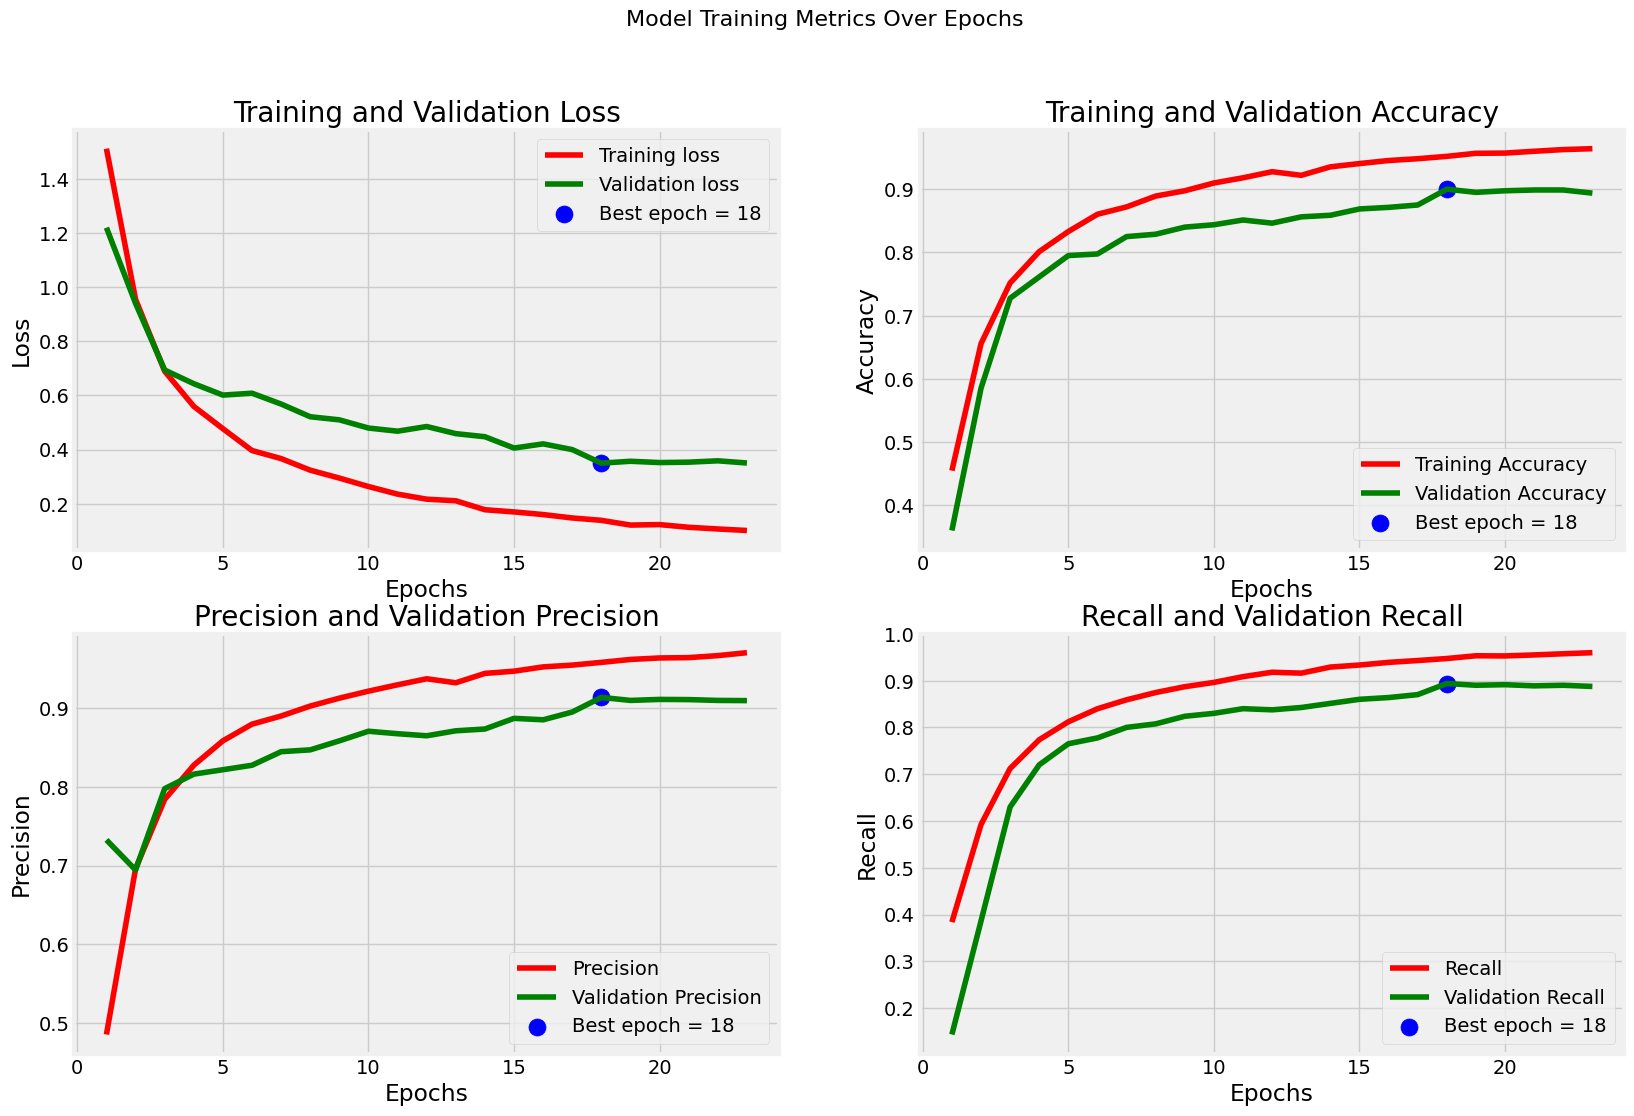

In [ ]:
tr_acc = history.history['accuracy']
tr_loss = history.history['loss']
tr_per = history.history['precision']
tr_recall = history.history['recall']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']
val_per = history.history['val_precision']
val_recall = history.history['val_recall']

index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]
index_precision = np.argmax(val_per)
per_highest = val_per[index_precision]
index_recall = np.argmax(val_recall)
recall_highest = val_recall[index_recall]

Epochs = [i + 1 for i in range(len(tr_acc))]
loss_label = f'Best epoch = {str(index_loss + 1)}'
acc_label = f'Best epoch = {str(index_acc + 1)}'
per_label = f'Best epoch = {str(index_precision + 1)}'
recall_label = f'Best epoch = {str(index_recall + 1)}'


plt.figure(figsize=(20, 12))
plt.style.use('fivethirtyeight')


plt.subplot(2, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label='Training loss')
plt.plot(Epochs, val_loss, 'g', label='Validation loss')
plt.scatter(index_loss + 1, val_lowest, s=150, c='blue', label=loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label='Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label='Validation Accuracy')
plt.scatter(index_acc + 1, acc_highest, s=150, c='blue', label=acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(Epochs, tr_per, 'r', label='Precision')
plt.plot(Epochs, val_per, 'g', label='Validation Precision')
plt.scatter(index_precision + 1, per_highest, s=150, c='blue', label=per_label)
plt.title('Precision and Validation Precision')
plt.xlabel('Epochs')
plt.ylabel('Precision')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 4)
plt.plot(Epochs, tr_recall, 'r', label='Recall')
plt.plot(Epochs, val_recall, 'g', label='Validation Recall')
plt.scatter(index_recall + 1, recall_highest, s=150, c='blue', label=recall_label)
plt.title('Recall and Validation Recall')
plt.xlabel('Epochs')
plt.ylabel('Recall')
plt.legend()
plt.grid(True)

plt.suptitle('Model Training Metrics Over Epochs', fontsize=16)
plt.show()

In [ ]:
train_score = model.evaluate(train_ds, verbose=1)
valid_score = model.evaluate(val_ds, verbose=1)
test_score = model.evaluate(test_ds, verbose=1)

print(f"Train Loss: {train_score[0]:.4f}")
print(f"Train Accuracy: {train_score[1]*100:.2f}%")
print('-' * 20)
print(f"Validation Loss: {valid_score[0]:.4f}")
print(f"Validation Accuracy: {valid_score[1]*100:.2f}%")
print('-' * 20)
print(f"Test Loss: {test_score[0]:.4f}")
print(f"Test Accuracy: {test_score[1]*100:.2f}%")

88/88 ━━━━━━━━━━━━━━━━━━━━ 43s 438ms/step - accuracy: 0.9861 - auc: 0.9995 - loss: 0.0478 - precision: 0.9885 - recall: 0.9839
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.9000 - auc: 0.9784 - loss: 0.3497 - precision: 0.9132 - recall: 0.8938
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.9950 - auc: 1.0000 - loss: 0.0253 - precision: 0.9962 - recall: 0.9925
Train Loss: 0.0478
Train Accuracy: 98.61%
--------------------
Validation Loss: 0.3497
Validation Accuracy: 90.00%
--------------------
Test Loss: 0.0253
Test Accuracy: 99.50%
